# 4 · Classify: which market is the idea in, and will it reach a million?

**Syllabus:** Module 4 (logistic regression, KNN, decision trees, model evaluation),
Module 6 (explainability).

Two classification problems sit inside the viability engine:

1. **Idea → category.** A user types a sentence; the engine must place it in one of 33
   categories. Trained on app *names only*, because a name is the closest thing in the
   data to a one-line idea. (The genre column would make it trivial, and an idea has
   no genre.)
2. **Success.** Will the app reach 1,000,000 installs? Using only what is known before
   launch.

Same 60/20/20 split as chapter 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)
import common as C
import engine as E

C.style()
apps = C.load_apps()
apps["split"] = C.split(apps)
apps["log_price"] = np.log1p(apps["price"])
tr, va, te = (apps[apps["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"])
now = C.load_2026()

## 4.1 Idea → category

**TF-IDF** turns text into numbers: each term gets a weight that is high when it is
frequent in this name and rare across all names. Two ways to cut a name into terms are
compared: whole **words**, and **character n-grams** (every 3 to 5 letter piece of
each word, so "calorie" and "calories" share most of their pieces). **Logistic
regression** (multinomial, one weight per term per category) turns the terms into a
probability for each category.

FAMILY is a catch-all: a fifth of the store, overlapping with games, education and
kids' apps. Left alone, the model sends any unclear idea there. **Balanced class
weights** make every category count equally in training. This costs some accuracy on
held-out apps (where FAMILY really is common) but gives a more useful answer for an
idea. Both are measured.

In [2]:
def top_k(model, X, y, k):
    P = model.predict_proba(X)
    order = np.argsort(-P, axis=1)[:, :k]
    yi = pd.Series(y).map({c: i for i, c in enumerate(model.classes_)}).to_numpy()
    return float((order == yi[:, None]).any(axis=1).mean())


grid = []
for analyzer, ngrams in [("word", (1, 2)), ("char_wb", (3, 5))]:
    vec = TfidfVectorizer(analyzer=analyzer, ngram_range=ngrams, sublinear_tf=True, min_df=2)
    Xtr, Xva = vec.fit_transform(tr["app"].map(E.normalise)), vec.transform(va["app"].map(E.normalise))
    for weight in [None, "balanced"]:
        for c in [1, 5, 20]:
            m = LogisticRegression(C=c, max_iter=3000, class_weight=weight).fit(Xtr, tr["category"])
            grid.append({"terms": analyzer, "weights": weight or "none", "C": c, "val_top1": top_k(m, Xva, va["category"], 1),
                         "val_top3": top_k(m, Xva, va["category"], 3),
                         "val_family_share": float((m.predict(Xva) == "FAMILY").mean())})
grid = pd.DataFrame(grid)
print(grid.round(3))
C.record("classify.category_grid", grid.round(4).to_dict(orient="records"))

      terms   weights   C  val_top1  val_top3  val_family_share
0      word      none   1     0.455     0.671             0.498
1      word      none   5     0.484     0.703             0.359
2      word      none  20     0.464     0.680             0.323
3      word  balanced   1     0.422     0.652             0.050
4      word  balanced   5     0.446     0.668             0.172
5      word  balanced  20     0.448     0.663             0.196
6   char_wb      none   1     0.459     0.683             0.525
7   char_wb      none   5     0.498     0.719             0.339
8   char_wb      none  20     0.493     0.707             0.288
9   char_wb  balanced   1     0.437     0.660             0.056
10  char_wb  balanced   5     0.461     0.698             0.106
11  char_wb  balanced  20     0.471     0.701             0.159


Character n-grams beat whole words. Among balanced models, the best C on validation
is used by the engine.

In [3]:
bal = grid[(grid["terms"] == "char_wb") & (grid["weights"] == "balanced")]
best_c = float(bal.sort_values("val_top1", ascending=False)["C"].iloc[0])
print("chosen C:", best_c)
C.record("classify.category_C", best_c)
assert best_c == E.CATEGORY_C, f"engine.CATEGORY_C is {E.CATEGORY_C} but validation chose {best_c}"

vec = E.vectorizer()
Xtr, Xte = vec.fit_transform(tr["app"].map(E.normalise)), vec.transform(te["app"].map(E.normalise))
cat_bal = LogisticRegression(C=best_c, max_iter=3000, class_weight="balanced").fit(Xtr, tr["category"])
cat_raw = LogisticRegression(C=best_c, max_iter=3000).fit(Xtr, tr["category"])
majority = tr["category"].mode()[0]
# The 2026 apps whose category also existed in 2018: names the model has never seen, from another era.
n26 = now[now["category"].isin(tr["category"].unique())]
X26 = vec.transform(n26["app"].map(E.normalise))
cat_test = {
    "majority_class": majority, "majority_top1": float((te["category"] == majority).mean()),
    "majority_top3": float(te["category"].isin(tr["category"].value_counts().index[:3]).mean()),
    "balanced_top1": top_k(cat_bal, Xte, te["category"], 1), "balanced_top3": top_k(cat_bal, Xte, te["category"], 3),
    "unbalanced_top1": top_k(cat_raw, Xte, te["category"], 1), "unbalanced_top3": top_k(cat_raw, Xte, te["category"], 3),
    "balanced_family_share": float((cat_bal.predict(Xte) == "FAMILY").mean()),
    "unbalanced_family_share": float((cat_raw.predict(Xte) == "FAMILY").mean()),
    "true_family_share": float((te["category"] == "FAMILY").mean()),
    "apps_2026": len(n26), "balanced_top1_2026": top_k(cat_bal, X26, n26["category"], 1),
    "balanced_top3_2026": top_k(cat_bal, X26, n26["category"], 3),
    "majority_top1_2026": float((n26["category"] == majority).mean()),
}
print(pd.Series(cat_test))
C.record("classify.category_test", cat_test)

chosen C: 20.0


majority_class               FAMILY
majority_top1              0.194099
majority_top3              0.377847
balanced_top1              0.482402
balanced_top3              0.703416
unbalanced_top1            0.489648
unbalanced_top3            0.718427
balanced_family_share      0.151656
unbalanced_family_share     0.29089
true_family_share          0.194099
apps_2026                      1647
balanced_top1_2026         0.621736
balanced_top3_2026         0.799029
majority_top1_2026              0.0
dtype: object


On 2026 names the model does *better* than on 2018 ones. Two reasons: the 2026 store
no longer has a FAMILY category (so the hardest confusion is gone), and the apps found
by search have descriptive names ("Calorie Counter - MyNetDiary") rather than brand
names. The model trained in 2018 still transfers to the store of 2026.

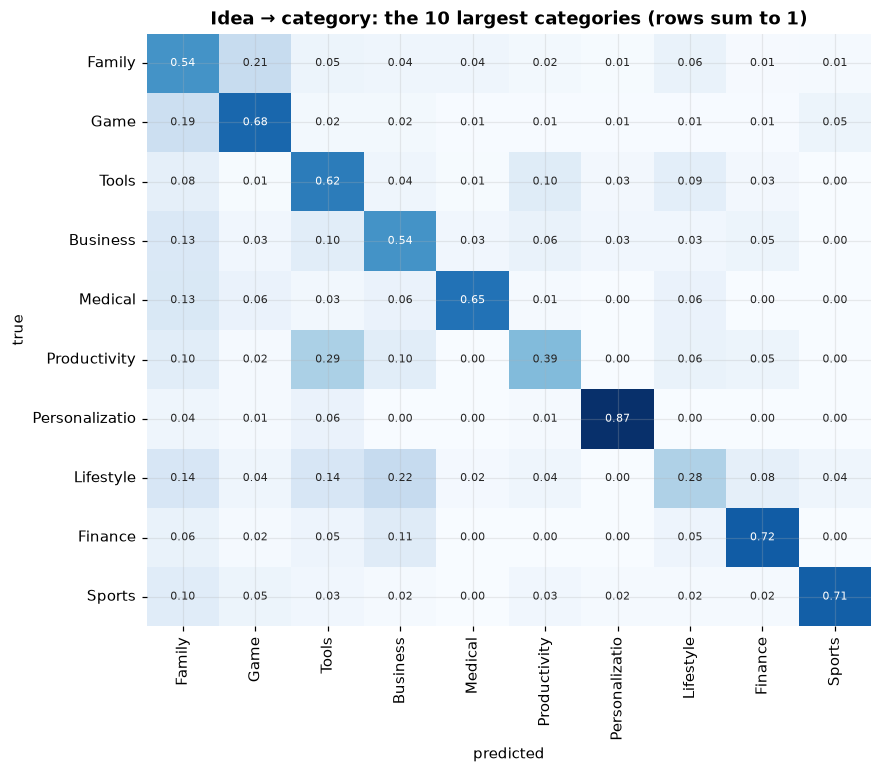

In [4]:
top10 = te["category"].value_counts().index[:10]
pred = cat_bal.predict(Xte)
mask = te["category"].isin(top10) & pd.Series(pred).isin(top10)
cm = confusion_matrix(te.loc[mask, "category"], pred[mask], labels=top10, normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 7))
lab = [c.replace("_", " ").title()[:14] for c in top10]
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=lab, yticklabels=lab, cbar=False, ax=ax, annot_kws={"size": 7})
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Idea → category: the 10 largest categories (rows sum to 1)")
C.save(fig, "classify_category_confusion")

The mistakes are understandable: FAMILY and GAME swap, and so do TOOLS and
PRODUCTIVITY. The store itself does not separate them sharply. This is why the app
shows the top three guesses and lets the user change the category.

## 4.2 Will it reach a million installs?

Target: installs ≥ 1,000,000 (35% of apps). Inputs, all knowable before launch:
category, content rating, free/paid, price, and the three neighbourhood signals of
chapter 3 (neighbours' installs, rating and closeness), leave-one-out on training apps.

Models: **logistic regression** without and with the neighbourhood, **KNN**
(majority vote of the K nearest apps in the same feature space) and a **decision
tree**. K and depth are chosen on validation by ROC AUC: the chance that a randomly
chosen successful app is ranked above a randomly chosen unsuccessful one (0.5 is
guessing, 1 is perfect).

                                            auc  accuracy  precision  recall  \
Logistic: + neighbourhood (engine)        0.826     0.752      0.706   0.564   
KNN (K = 51): + neighbourhood             0.818     0.751      0.695   0.578   
Decision tree (depth 8): + neighbourhood  0.796     0.731      0.667   0.542   
Logistic: category, content, price        0.728     0.680      0.626   0.331   
Always 'not successful'                   0.500     0.630      0.000   0.000   

                                             f1  
Logistic: + neighbourhood (engine)        0.627  
KNN (K = 51): + neighbourhood             0.631  
Decision tree (depth 8): + neighbourhood  0.598  
Logistic: category, content, price        0.433  
Always 'not successful'                   0.000  


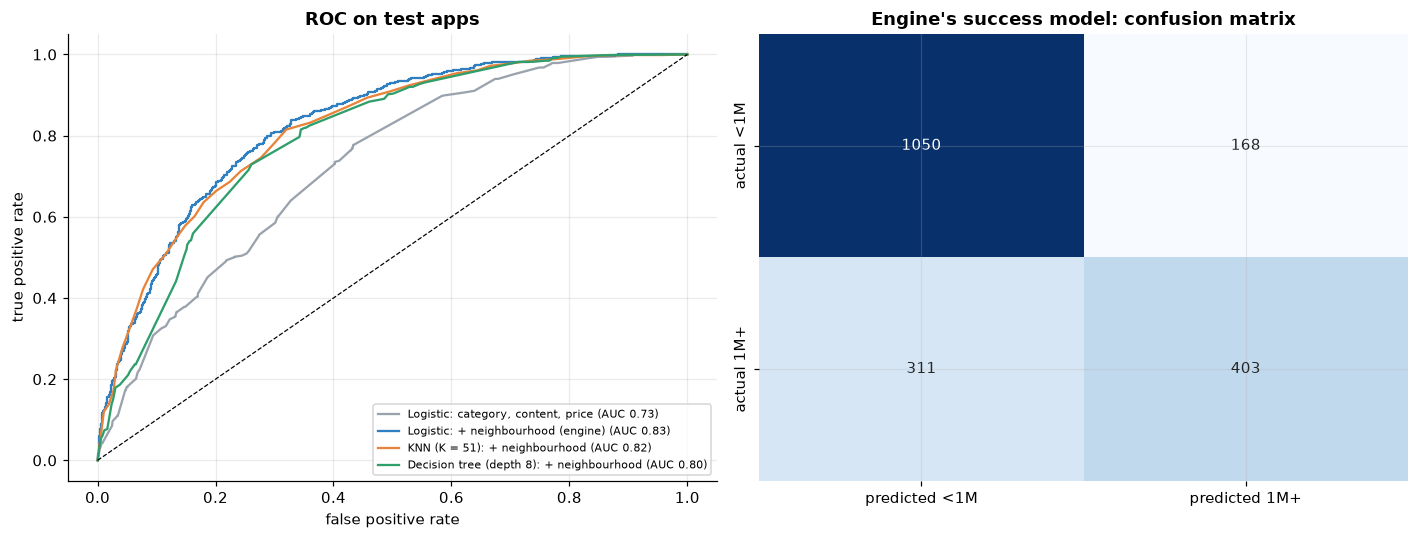

In [5]:
eng = E.fit(tr.drop(columns="split"))


def with_signals(d, exclude=None):
    X = eng.vec.transform(d["app"].map(E.normalise))
    sim, idx = eng.neighbours(X, exclude=exclude)
    return d.join(eng.signals(sim, idx))


trs, vas, tes = with_signals(tr, np.arange(len(tr))), with_signals(va), with_signals(te)
base = ["category", "content", "paid", "log_price"]
full = base + ["nb_demand", "nb_crowding", "nb_rating"]


def prep(cols):
    return ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["category", "content"]),
                              ("num", StandardScaler(), [c for c in cols if c not in ("category", "content")])])


models = {"Logistic: category, content, price": (make_pipeline(prep(base), LogisticRegression(max_iter=2000)), base)}
models["Logistic: + neighbourhood (engine)"] = (E.success_pipeline(), full)
k_auc = {k: roc_auc_score(vas["success"], make_pipeline(prep(full), KNeighborsClassifier(k)).fit(trs[full], trs["success"]).predict_proba(vas[full])[:, 1])
         for k in [5, 15, 25, 51, 101]}
best_k = max(k_auc, key=k_auc.get)
models[f"KNN (K = {best_k}): + neighbourhood"] = (make_pipeline(prep(full), KNeighborsClassifier(best_k)), full)
d_auc = {d: roc_auc_score(vas["success"], make_pipeline(prep(full), DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=C.SEED))
                          .fit(trs[full], trs["success"]).predict_proba(vas[full])[:, 1]) for d in [2, 3, 4, 5, 6, 8, 10]}
best_d = max(d_auc, key=d_auc.get)
models[f"Decision tree (depth {best_d}): + neighbourhood"] = (make_pipeline(prep(full), DecisionTreeClassifier(max_depth=best_d, min_samples_leaf=20, random_state=C.SEED)), full)
C.record("classify.success_knn_val_auc", k_auc); C.record("classify.success_tree_val_auc", d_auc)

rows, curves = {}, {}
for name, (m, cols) in models.items():
    m.fit(trs[cols], trs["success"])
    p = m.predict_proba(tes[cols])[:, 1]
    yhat = (p >= 0.5).astype(int)
    rows[name] = {"auc": roc_auc_score(tes["success"], p), "accuracy": accuracy_score(tes["success"], yhat),
                  "precision": precision_score(tes["success"], yhat, zero_division=0), "recall": recall_score(tes["success"], yhat),
                  "f1": f1_score(tes["success"], yhat)}
    curves[name] = roc_curve(tes["success"], p)
rows["Always 'not successful'"] = {"auc": 0.5, "accuracy": float(1 - tes["success"].mean()), "precision": 0.0, "recall": 0.0, "f1": 0.0}
stab = pd.DataFrame(rows).T.sort_values("auc", ascending=False)
print(stab.round(3))
C.record("classify.success_table", stab.round(4).to_dict(orient="index"))
C.record("classify.success_rate_test", float(tes["success"].mean()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (name, (fpr, tpr, _)), col in zip(curves.items(), [C.PALETTE["muted"], C.PALETTE["main"], C.PALETTE["accent"], C.PALETTE["good"]]):
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {rows[name]['auc']:.2f})", color=col)
axes[0].plot([0, 1], [0, 1], ls="--", color="k", lw=0.8)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].legend(fontsize=7)
axes[0].set_title("ROC on test apps")
eng_name = "Logistic: + neighbourhood (engine)"
cm = confusion_matrix(tes["success"], (models[eng_name][0].predict_proba(tes[full])[:, 1] >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["predicted <1M", "predicted 1M+"], yticklabels=["actual <1M", "actual 1M+"])
axes[1].set_title("Engine's success model: confusion matrix")
fig.tight_layout(); C.save(fig, "classify_success")

## 4.3 Why the engine says what it says

Logistic regression is used in the engine, not because it wins by a wide margin, but
because its weights can be read: each one says how much an input raises or lowers the
odds of reaching a million installs, with everything else held fixed. Inputs are
standardised, so the numeric weights are comparable.

category_MEDICAL               -1.42
category_BEAUTY                -1.38
category_DATING                -1.20
category_LIBRARIES_AND_DEMO    -0.98
category_ART_AND_DESIGN        -0.88
category_AUTO_AND_VEHICLES     -0.79
category_EVENTS                -0.76
category_BUSINESS              -0.60
category_PHOTOGRAPHY            0.50
category_MAPS_AND_NAVIGATION    0.52
category_GAME                   0.54
category_SHOPPING               0.67
category_VIDEO_PLAYERS          0.82
nb_demand                       1.09
category_EDUCATION              1.15
category_ENTERTAINMENT          1.88
dtype: float64


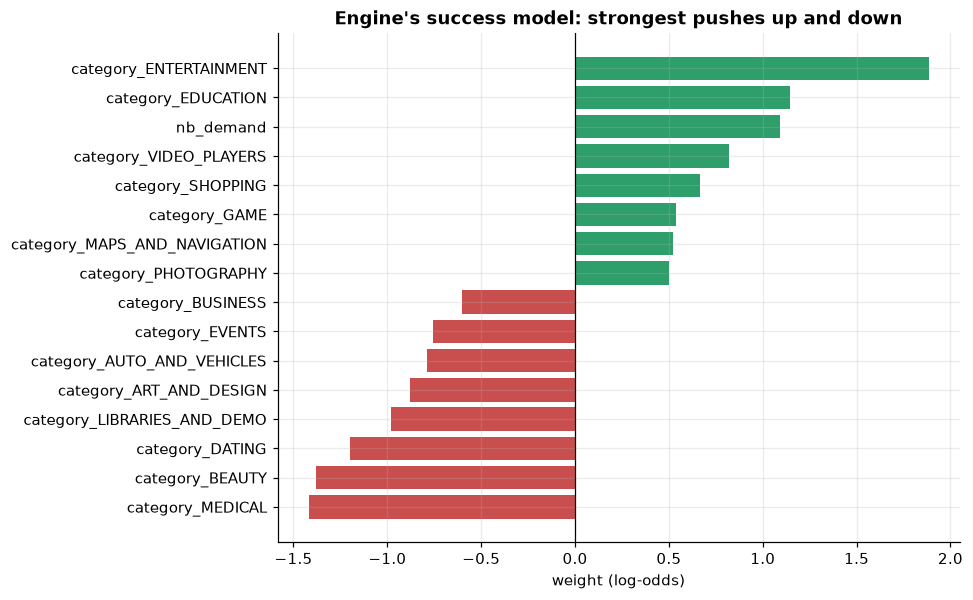

In [6]:
m = models[eng_name][0]
w = pd.Series(m[-1].coef_[0], m[0].get_feature_names_out())
w.index = w.index.str.replace("cat__", "").str.replace("num__", "")
show = pd.concat([w.sort_values().head(8), w.sort_values().tail(8)])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(show.index, show.values, color=[C.PALETTE["bad"] if v < 0 else C.PALETTE["good"] for v in show.values])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("weight (log-odds)")
ax.set_title("Engine's success model: strongest pushes up and down")
C.save(fig, "classify_weights")
C.record("classify.engine_weights", w.round(4).to_dict())
print(show.round(2))